In [12]:
import pandas as pd 
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder , MinMaxScaler
from sklearn.model_selection import train_test_split 

In [13]:
heart_data = pd.read_csv("Heart_dataset.csv")
heart_data

,Unnamed: 0,Age,Sex,ChestPain,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,Thal,AHD
0,1,63,1,typical,145.0,233,1.0,2.0,150.0,0.0,2.3,3.0,0.0,fixed,No
1,2,67,1,asymptomatic,160.0,286,0.0,2.0,108.0,1.0,1.5,2.0,3.0,normal,Yes
2,3,67,1,asymptomatic,120.0,229,0.0,2.0,129.0,1.0,2.6,2.0,2.0,reversable,Yes
3,4,37,1,nonanginal,130.0,250,0.0,0.0,187.0,0.0,3.5,3.0,0.0,normal,No
4,5,41,0,nontypical,130.0,204,0.0,2.0,172.0,0.0,1.4,1.0,0.0,normal,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,299,45,1,typical,110.0,264,0.0,0.0,132.0,0.0,1.2,2.0,0.0,reversable,Yes
299,300,68,1,asymptomatic,144.0,193,1.0,0.0,141.0,0.0,3.4,2.0,2.0,reversable,Yes
300,301,57,1,asymptomatic,130.0,131,0.0,0.0,115.0,1.0,1.2,2.0,1.0,reversable,Yes
301,302,57,0,nontypical,130.0,236,0.0,2.0,174.0,0.0,0.0,2.0,1.0,normal,Yes


In [11]:
heart_data = heart_data.drop( columns = ["Unnamed: 0"] )
heart_data

,Age,Sex,ChestPain,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,Thal,AHD
0,63,1,typical,145.0,233,1.0,2.0,150.0,0.0,2.3,3.0,0.0,fixed,No
1,67,1,asymptomatic,160.0,286,0.0,2.0,108.0,1.0,1.5,2.0,3.0,normal,Yes
2,67,1,asymptomatic,120.0,229,0.0,2.0,129.0,1.0,2.6,2.0,2.0,reversable,Yes
3,37,1,nonanginal,130.0,250,0.0,0.0,187.0,0.0,3.5,3.0,0.0,normal,No
4,41,0,nontypical,130.0,204,0.0,2.0,172.0,0.0,1.4,1.0,0.0,normal,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,45,1,typical,110.0,264,0.0,0.0,132.0,0.0,1.2,2.0,0.0,reversable,Yes
299,68,1,asymptomatic,144.0,193,1.0,0.0,141.0,0.0,3.4,2.0,2.0,reversable,Yes
300,57,1,asymptomatic,130.0,131,0.0,0.0,115.0,1.0,1.2,2.0,1.0,reversable,Yes
301,57,0,nontypical,130.0,236,0.0,2.0,174.0,0.0,0.0,2.0,1.0,normal,Yes


In [5]:
heart_data.mean(numeric_only = True )

Age         54.438944
Sex          0.679868
RestBP     131.662252
Chol       246.693069
Fbs          0.149007
RestECG      0.986755
MaxHR      149.674419
ExAng        0.324503
Oldpeak      1.039604
Slope        1.602649
Ca           0.672241
dtype: float64

In [6]:
heart_data.median( numeric_only = True )

Age         56.0
Sex          1.0
RestBP     130.0
Chol       241.0
Fbs          0.0
RestECG      0.5
MaxHR      153.0
ExAng        0.0
Oldpeak      0.8
Slope        2.0
Ca           0.0
dtype: float64

In [7]:
heart_data.mode( numeric_only = True)

,Age,Sex,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca
0,58.0,1.0,120.0,197,0.0,0.0,162.0,0.0,0.0,1.0,0.0
1,NaN,NaN,NaN,204,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,234,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
#handling categorical data by encoding
label_enc = LabelEncoder()

#categorical columns
cols = [ "ChestPain" , "Thal" , "AHD" ]

#encoding columns
for col in cols:
    heart_data[col] = label_enc.fit_transform(heart_data[col])

In [9]:
heart_data.isnull().any()

Age          False
Sex          False
ChestPain    False
RestBP        True
Chol         False
Fbs           True
RestECG       True
MaxHR         True
ExAng         True
Oldpeak      False
Slope         True
Ca            True
Thal         False
AHD          False
dtype: bool

In [10]:
heart_data.isnull().sum()

Age          0
Sex          0
ChestPain    0
RestBP       1
Chol         0
Fbs          1
RestECG      1
MaxHR        2
ExAng        1
Oldpeak      0
Slope        1
Ca           4
Thal         0
AHD          0
dtype: int64

In [11]:
#handling missing values
heart_data["RestBP"] = heart_data["RestBP"].fillna( heart_data["RestBP"].mean() )
heart_data["Fbs"]= heart_data["Fbs"].fillna( heart_data["Fbs"].median() )

heart_data["RestECG"] = heart_data["RestECG"].fillna(heart_data.RestECG.median())
heart_data["MaxHR"] = heart_data["MaxHR"].fillna(heart_data.MaxHR.median())
heart_data["ExAng"] = heart_data["ExAng"].fillna(heart_data.ExAng.median())
heart_data["Slope"] = heart_data["Slope"].fillna(heart_data.Slope.median())
heart_data["Ca"] = heart_data["Ca"].fillna(heart_data.Ca.median())
heart_data["Thal"] = heart_data["Thal"].fillna(heart_data.Thal.median())


In [12]:
#missing values got filled
heart_data.isnull().sum()

Age          0
Sex          0
ChestPain    0
RestBP       0
Chol         0
Fbs          0
RestECG      0
MaxHR        0
ExAng        0
Oldpeak      0
Slope        0
Ca           0
Thal         0
AHD          0
dtype: int64

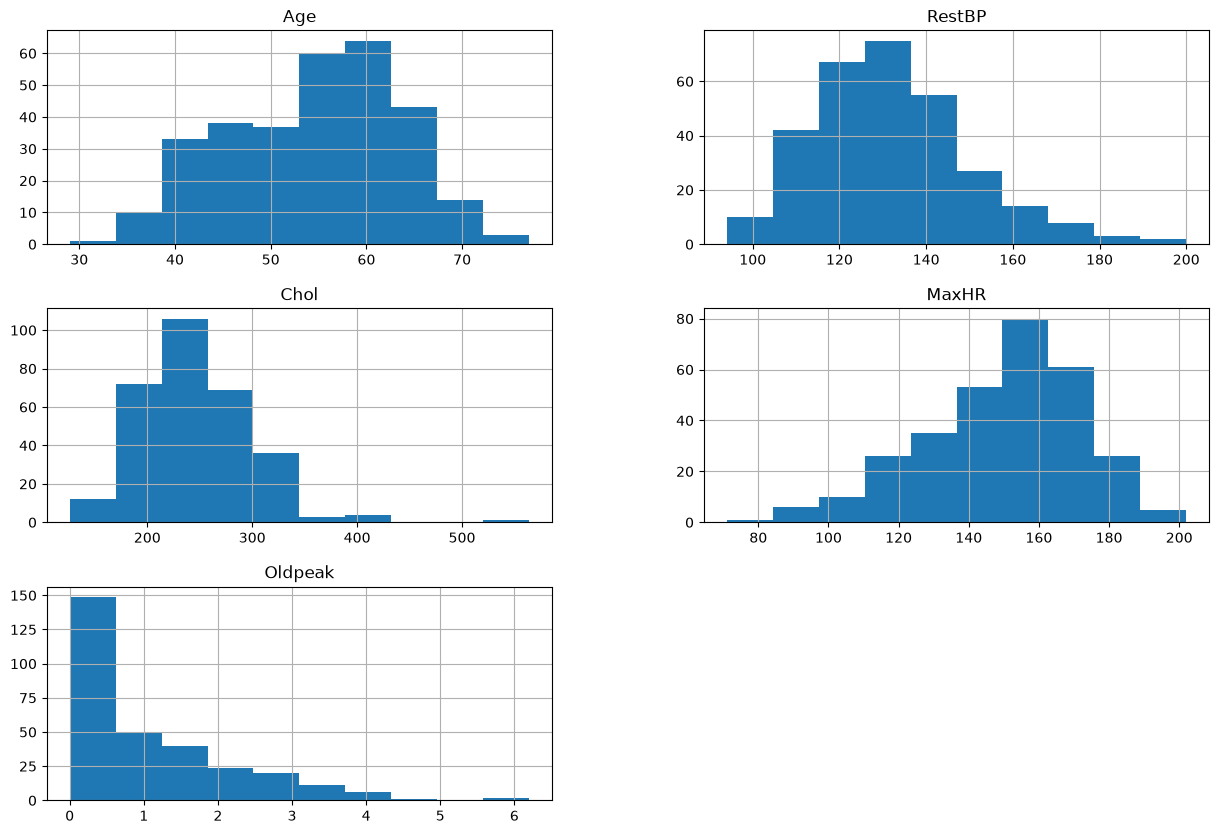

In [19]:
#plotting histogram
heart_data[["Age", "RestBP", "Chol" , "MaxHR", "Oldpeak"]].hist( figsize=(15,10))
plt.show()

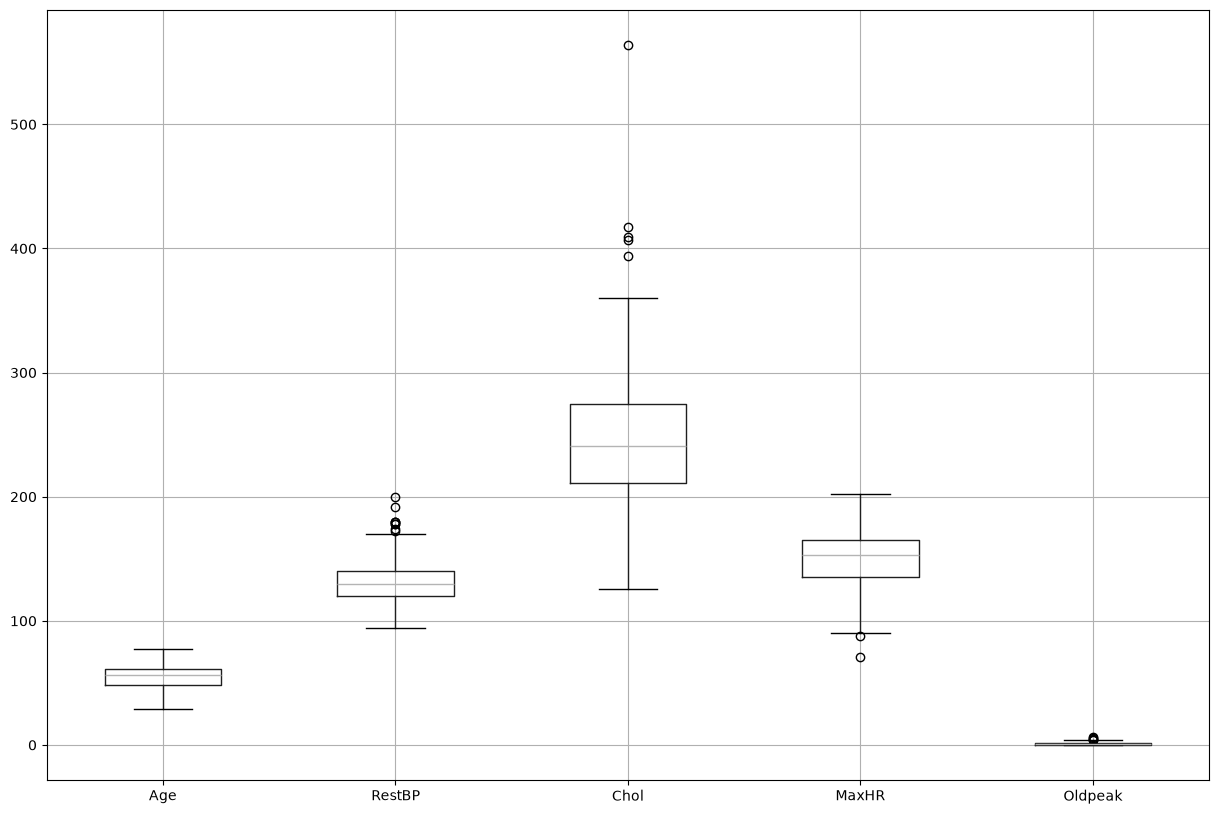

In [30]:
#plotting boxplot
plt.figure(figsize=(15,10))
heart_data[["Age", "RestBP", "Chol", "MaxHR", "Oldpeak"]].boxplot()
plt.show()

In [31]:
#splitting the dataset

x = heart_data.drop(columns=["AHD"])
y = heart_data["AHD"]

In [34]:
x.head()

,Age,Sex,ChestPain,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,Thal
0,63,1,3,145.0,233,1.0,2.0,150.0,0.0,2.3,3.0,0.0,0
1,67,1,0,160.0,286,0.0,2.0,108.0,1.0,1.5,2.0,3.0,1
2,67,1,0,120.0,229,0.0,2.0,129.0,1.0,2.6,2.0,2.0,2
3,37,1,1,130.0,250,0.0,0.0,187.0,0.0,3.5,3.0,0.0,1
4,41,0,2,130.0,204,0.0,2.0,172.0,0.0,1.4,1.0,0.0,1


In [35]:
y.head()

0    0
1    1
2    1
3    0
4    0
Name: AHD, dtype: int64

In [37]:
#splitting the dataset into traning and testing
x_train , x_test , y_train , y_test = train_test_split( x , y , train_size=0.8 , random_state=42)

In [38]:
#feature scaling
continuous_cols = ['Age', 'RestBP', 'Chol', 'MaxHR', 'Oldpeak']

min_max_scaler = MinMaxScaler()

x_train[continuous_cols] = min_max_scaler.fit_transform(x_train[continuous_cols])
x_test[continuous_cols] = min_max_scaler.transform(x_test[continuous_cols])



In [40]:
x_train

,Age,Sex,ChestPain,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,Thal
132,0.000000,1,2,0.339623,0.268041,0.0,2.0,1.000000,0.0,0.000000,1.0,0.0,1
202,0.583333,1,1,0.528302,0.000000,1.0,0.0,0.778626,0.0,0.032258,1.0,1.0,2
196,0.833333,1,3,0.622642,0.371134,1.0,2.0,0.458015,0.0,0.016129,2.0,1.0,1
75,0.750000,0,1,0.622642,0.804124,0.0,2.0,0.610687,0.0,0.129032,1.0,0.0,1
176,0.479167,1,0,0.132075,0.367698,1.0,0.0,0.580153,0.0,0.016129,1.0,3.0,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...
188,0.520833,1,2,0.924528,0.539519,0.0,2.0,0.946565,0.0,0.000000,1.0,1.0,2
71,0.791667,1,0,0.292453,0.439863,1.0,0.0,0.702290,0.0,0.032258,2.0,2.0,2
106,0.625000,1,0,0.433962,0.175258,0.0,0.0,0.694656,1.0,0.000000,1.0,1.0,2
270,0.666667,1,0,0.433962,0.278351,0.0,2.0,0.511450,1.0,0.306452,1.0,1.0,2


In [41]:
x_test

,Age,Sex,ChestPain,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,Thal
179,0.500000,1,1,0.339623,0.412371,1.0,2.0,0.778626,0.0,0.000000,1.0,3.0,1
228,0.520833,1,0,0.150943,0.274914,0.0,2.0,0.282443,1.0,0.000000,2.0,1.0,1
111,0.562500,1,0,0.292453,0.422680,1.0,2.0,0.557252,1.0,0.193548,2.0,1.0,1
246,0.604167,1,0,0.056604,0.371134,0.0,0.0,0.648855,0.0,0.016129,1.0,1.0,2
60,0.458333,0,0,0.339623,0.615120,0.0,0.0,0.541985,1.0,0.193548,2.0,0.0,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...
249,0.687500,1,2,0.320755,0.281787,1.0,2.0,0.526718,0.0,0.000000,1.0,0.0,1
104,0.416667,1,1,0.245283,0.213058,0.0,0.0,0.519084,0.0,0.322581,2.0,3.0,2
300,0.583333,1,0,0.339623,0.017182,0.0,0.0,0.335878,1.0,0.193548,2.0,1.0,2
193,0.687500,0,0,0.415094,0.577320,1.0,0.0,0.267176,0.0,0.306452,2.0,3.0,1


In [ ]:
# import pandas as pd

# import matplotlib.pyplot as plt

# from sklearn.model_selection import train_test_split

# from sklearn.preprocessing import LabelEncoder, StandardScaler

 

# #Load dataset

# df = pd.read_csv("Cafe_Sales.csv")

 

# #Missing and duplicate handling

# df = df.drop_duplicates()

# df = df.replace("UNKNOWN", pd.NA)

 

# df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")

# df["Price Per Unit"] = pd.to_numeric(df["Price Per Unit"], errors="coerce")

# df["Total Spent"] = pd.to_numeric(df["Total Spent"], errors="coerce")

 

# df["Quantity"] = df["Quantity"].fillna(df["Quantity"].median())

# df["Price Per Unit"] = df["Price Per Unit"].fillna(df["Price Per Unit"].median())

# df["Total Spent"] = df["Total Spent"].fillna(df["Total Spent"].median())

 

# df["Item"] = df["Item"].fillna(df["Item"].mode()[0])

# df["Payment Method"] = df["Payment Method"].fillna(df["Payment Method"].mode()[0])

# df["Location"] = df["Location"].fillna(df["Location"].mode()[0])

 

# #Statistical analysis

# print(df.describe(),"\n")

# print("Quantity:\n Median:",df["Quantity"].median(),"\n Mode:",df["Quantity"].mode()[0])

# print("\nPrice Per Unit:\n Median:",df["Price Per Unit"].median(),"\n Mode:",df["Price Per Unit"].mode()[0])

# print("\nTotal Spent:\n Median:",df["Total Spent"].median(),"\n Mode:",df["Total Spent"].mode()[0])

 

# #Data splitting

# X = df.drop(["Total Spent", "Transaction ID", "Transaction Date"], axis=1)

# y = df["Total Spent"]

 

# X_train, X_test, y_train, y_test = train_test_split(

# X, y, test_size=0.2, random_state=42

# )

 

# # Label Encoding

# le = LabelEncoder()

 

# df["Item"] = le.fit_transform(df["Item"])

# df["Payment Method"] = le.fit_transform(df["Payment Method"])

# df["Location"] = le.fit_transform(df["Location"])

 

# # Feature scaling

# scaler = StandardScaler()

 

# X_train = scaler.fit_transform(X_train)

# X_test = scaler.transform(X_test)

 

# print("Training data:", X_train.shape)

# print("Testing data:", X_test.shape)

 

# #Histograms

# df.hist(figsize = (10,8))

# plt.show()

 

# # 8. Boxplots

# df.plot(kind="box", figsize=(10, 6))

# plt.show()

 

 